# Milestone 4 figures: training curves, calibration and sample predictions

This notebook draws the Milestone 4 report's figures from saved files. It trains nothing and runs no model
on a photo: every curve, score and verdict below is read from a run's saved outputs, or recomputed from
them with the repo's own functions, and each is checked against the number the run recorded. It runs on a
laptop's CPU in about a minute, most of it fetching 20 photos, and writes PNG files and a credits table to
`documentation/milestone 4/assets/`, where `figures.md` captions each one; the two photo figures are saved,
not displayed. It needs the Kaggle outputs `sg-m4-full-a3`, `sg-m4-gate` and `sg-m4-non-snake` and the clean
dataset's `metadata.csv` beside the repo (see `results/m4/artifacts.md`).

1. **Learning curves** of the three full runs (A1, H2 and A3), from `results/m4/full/<run>/metrics.jsonl`.
2. **Reliability** of A3's species probabilities on the validation photos, before and after temperature
   scaling, from A3's saved validation outputs and the temperature in its `decision_metrics.json`.
3. **Sample predictions**: 8 right and 8 wrong A3 predictions on validation photos, each with the
   detector's box, the true species, the top 3 and the verdict with its reason; then 4
   non-snake validation photos that the app's gate called a snake, with the gate's scores.

A photo is shown only if its licence is CC0 or CC BY. Each is fetched from its source url, checked against
the dataset (the SHA-1 for a snake photo; the size and pHash for a non-snake photo, as
`scripts/fetch_non_snake_test.py` checks them), kept outside the repo, and credited in
`sample_predictions_credits.csv`. Only validation photos are used; the test split stays closed.

In [1]:
import hashlib, http.client, json, os, sys, textwrap, urllib.request, warnings
from pathlib import Path

os.environ.update(YOLO_VERBOSE="False", YOLO_OFFLINE="1", NO_ALBUMENTATIONS_UPDATE="1")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

sys.path.insert(0, "../src")
from serpentguard import decide, front_end, metrics, negatives

WORK = Path("../..")  # the folder beside the repo
A3_OUTPUT = Path(os.environ.get("A3_OUTPUT", WORK / "kaggle/m4_runs/full_a3/out_jayesh"))  # jayeshbansal497/sg-m4-full-a3
GATE_OUTPUT = Path(os.environ.get("GATE_OUTPUT", WORK / "kaggle/m4_runs/gate/out_full"))  # puneetbajajiitm/sg-m4-gate
NON_SNAKE_OUTPUT = Path(os.environ.get("NON_SNAKE_OUTPUT", WORK / "kaggle/m4_runs/non_snake/out_full"))  # puneetbajajiitm/sg-m4-non-snake
METADATA = Path(os.environ.get("METADATA", WORK / "kaggle/clean_build/out/metadata.csv"))  # the clean dataset's
PHOTO_CACHE = Path(os.environ.get("PHOTO_CACHE", WORK / "m4-figure-photos"))  # fetched photos, never committed
RESULTS = Path("../results/m4")
ASSETS = Path("../documentation/milestone 4/assets")
A3_RUN = A3_OUTPUT / "M4_FULL"
RUNS = {"A1": "A1: box crop + scenery swap", "H2": "H2: A1 + detail crop",
        "A3": "A3: mask-box crop + scenery swap (shipped)"}
LOSSES = {"species": "species (ArcFace)", "genus": "genus", "family": "family", "who": "WHO", "total": "total"}
LOSS_WEIGHTS = {"genus": 0.3, "family": 0.3, "who": 0.5}  # models.total_loss: species + 0.3 (genus + family) + 0.5 WHO
SCORES = {"macro_f1": "macro-F1", "top1": "top-1", "top3": "top-3"}
EVAL_EPOCHS = list(range(2, 31, 2))  # 30 epochs, scored every second one
BINS = 15  # metrics.calibration's bins
SHOWN_LICENCES = ("cc0", "cc-by")
PHOTO_HOST = "https://inaturalist-open-data.s3.amazonaws.com/"  # the one photo host this notebook fetches from
N_RIGHT, N_WRONG, N_FALSE_SNAKES, SEED = 8, 8, 4, 42
VERDICT_TEXT = {"dangerous": "dangerous", "not_listed": "not on the WHO list", "unknown": "we don't know"}
WHO_TEXT = {"1": "WHO Category 1", "2": "WHO Category 2", "not_listed": "not WHO-listed"}
TEXT_WIDTH = 46  # characters per line under a photo
PANEL_FONTS = ["DejaVu Sans Mono", "Arial Unicode MS"]  # the second draws the photographers' names in other scripts
USER_AGENT = "SerpentGuardStudentProject/1.0"
FETCH_ATTEMPTS, TIMEOUT_SECONDS = 5, 60
DPI, PHOTO_DPI = 110, 90  # the photo figures at a lower resolution keep their PNGs small
for folder in (ASSETS, PHOTO_CACHE / "val", PHOTO_CACHE / "non_snake"):
    folder.mkdir(parents=True, exist_ok=True)


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


shipped = json.loads((RESULTS / "full/A3/manifest.json").read_text())["not_in_repo"]
for name, recorded in (("val_outputs.npz", "M4_FULL/val_outputs.npz"), ("prototypes.npz", "M4_FULL/prototypes.npz")):
    assert sha256(A3_RUN / name) == shipped[recorded]["sha256"], f"{name} is not A3's"
assert sha256(A3_OUTPUT / "full/frontend_preds.csv") == shipped["full/frontend_preds.csv"]["sha256"]
print("A3's validation outputs, prototypes and front-end file match the run's manifest.json")

A3's validation outputs, prototypes and front-end file match the run's manifest.json


## 1. Learning curves

`train` logs one row per evaluated epoch (every second epoch, 15 rows for 30 epochs): the mean training loss
of that epoch's batches, per head and in total, and the validation macro-F1, top-1 and top-3. Validation
loss was never computed, so there is no validation loss curve. The total is the weighted sum the optimiser
minimises, species + 0.3 (genus + family) + 0.5 WHO (`models.total_loss`); the check below recomputes it
from the logged heads. The best epoch is the one `train` kept, the highest validation macro-F1.

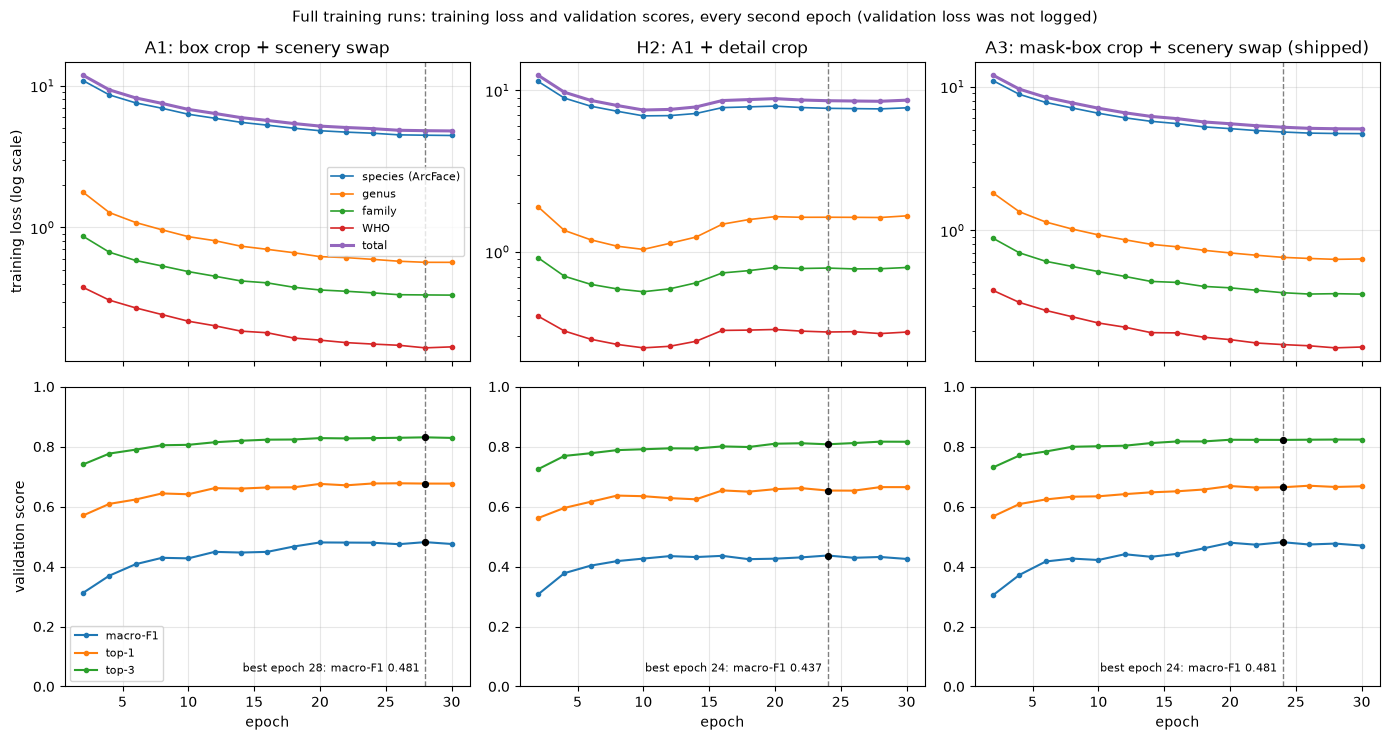

,macro_f1,top1,top3,loss_total,best_epoch
A1,0.4815,0.6767,0.8309,4.8182,28
H2,0.4368,0.6535,0.8077,8.6271,24
A3,0.4812,0.6644,0.8223,5.2177,24


In [2]:
history = {run: pd.read_json(RESULTS / "full" / run / "metrics.jsonl", lines=True) for run in RUNS}
best = {run: json.loads((RESULTS / "full" / run / "final_metrics.json").read_text())["run"]["best_epoch"]
        for run in RUNS}
for run, rows in history.items():
    assert rows["epoch"].tolist() == EVAL_EPOCHS, f"{run}: not every second epoch"
    assert rows.loc[rows["macro_f1"].idxmax(), "epoch"] == best[run], f"{run}: best epoch is not the best macro-F1"
    total = rows["loss_species"] + sum(w * rows[f"loss_{head}"] for head, w in LOSS_WEIGHTS.items())
    assert np.allclose(total, rows["loss_total"], atol=1e-3), f"{run}: total is not the weighted sum"

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for column, (run, title) in enumerate(RUNS.items()):
    rows, top, bottom = history[run], axes[0, column], axes[1, column]
    for head, label in LOSSES.items():
        top.plot(rows["epoch"], rows[f"loss_{head}"], marker="o", ms=3, label=label,
                 lw=2.2 if head == "total" else 1.2)
    for score, label in SCORES.items():
        bottom.plot(rows["epoch"], rows[score], marker="o", ms=3, label=label)
    at_best = rows.set_index("epoch").loc[best[run]]
    bottom.scatter([best[run]] * 3, [at_best[s] for s in SCORES], color="black", zorder=3, s=18)
    for ax in (top, bottom):
        ax.axvline(best[run], color="grey", ls="--", lw=1)
        ax.grid(alpha=0.3)
    top.set(title=title, yscale="log", ylabel="training loss (log scale)" if column == 0 else None)
    bottom.set(xlabel="epoch", ylim=(0, 1), ylabel="validation score" if column == 0 else None)
    bottom.annotate(f"best epoch {best[run]}: macro-F1 {at_best['macro_f1']:.3f}", (best[run], 0.05),
                    xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=8)
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("Full training runs: training loss and validation scores, every second epoch "
             "(validation loss was not logged)", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "learning_curves.png", dpi=DPI)
plt.show()
pd.DataFrame({run: history[run].set_index("epoch").loc[best[run], ["macro_f1", "top1", "top3", "loss_total"]]
              for run in RUNS}).T.assign(best_epoch=best).round(4)

## 2. Reliability before and after temperature scaling

A3's decision file fits a temperature on the calibration photos (`decide.fit_temperature`) and every verdict
reads the species probabilities divided by it. Here the validation photos' confidence (the top species'
probability) is binned into the 15 bins of `metrics.calibration`, and each bin's share of right answers is
drawn against its mean confidence, once with the raw softmax and once with the temperature. The expected
calibration error (ECE) of each must equal the one in `decision_metrics.json`.

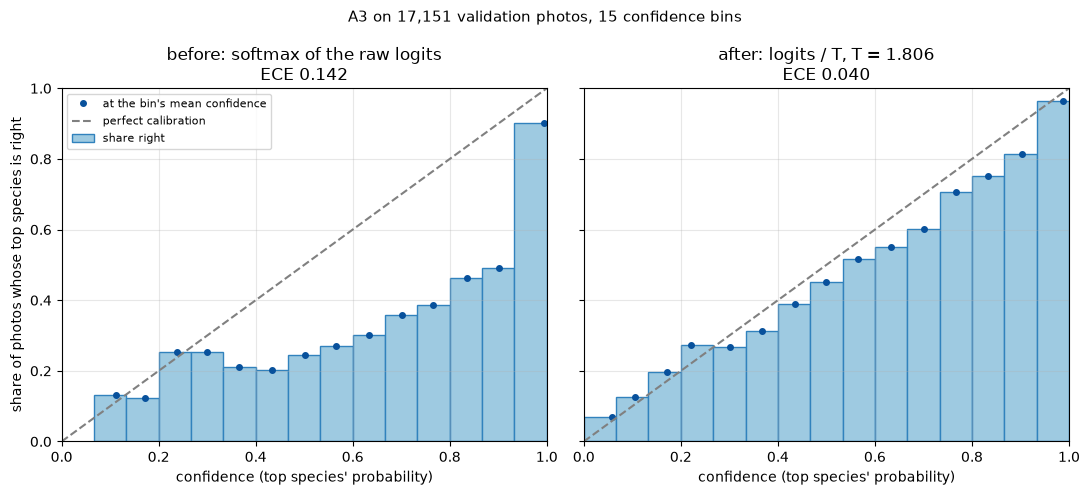

low   high  photos  accuracy  confidence
temperature scaling                                               
before              0   0.000  0.067       0     0.000       0.000
                    1   0.067  0.133      46     0.130       0.113
                    2   0.133  0.200     179     0.123       0.172
                    3   0.200  0.267    1490     0.252       0.238
                    4   0.267  0.333     586     0.253       0.299
                    5   0.333  0.400     464     0.211       0.365
                    6   0.400  0.467     420     0.202       0.434
                    7   0.467  0.533     507     0.245       0.502
                    8   0.533  0.600     470     0.270       0.566
                    9   0.600  0.667     472     0.301       0.634
                    10  0.667  0.733     461     0.358       0.701
                    11  0.733  0.800     470     0.385       0.765
                    12  0.800  0.867     543     0.464       0.836
                    13  0.867  0.933     735     0.491       0.902
                    14  0.933  1.000   10308     0.903       0.995
after               0   0.000  0.067      43     0.070       0.058
                    1   0.067  0.133     610     0.125       0.107
                    2   0.133  0.200    1131     0.195       0.172
                    3   0.200  0.267    1923     0.274       0.221
                    4   0.267  0.333     675     0.268       0.300
                    5   0.333  0.400     606     0.312       0.366
                    6   0.400  0.467     518     0.390       0.434
                    7   0.467  0.533     502     0.452       0.500
                    8   0.533  0.600     492     0.516       0.566
                    9   0.600  0.667     462     0.552       0.633
                    10  0.667  0.733     464     0.601       0.701
                    11  0.733  0.800     502     0.705       0.767
                    12  0.800  0.867     592     0.752       0.833
                    13  0.867  0.933     946     0.814       0.903
                    14  0.933  1.000    7685     0.965       0.988

In [3]:
decision = json.loads((RESULTS / "full/A3/decision_metrics.json").read_text())
temperature = decision["thresholds"]["temperature"]
val = decide.load_outputs(A3_RUN / "val_outputs.npz")
logits = np.asarray(val["species_logits"], dtype=float)
probs = {"before": metrics.softmax(logits), "after": metrics.softmax(logits / temperature)}


def reliability(p, labels, bins=BINS):
    """Per confidence bin, (low, high] as in metrics.calibration: photos, share right, mean confidence."""
    confidence, right = p.max(axis=1), p.argmax(axis=1) == labels
    edges = np.linspace(0, 1, bins + 1)
    bin_of = np.searchsorted(edges[1:-1], confidence, side="left")
    photos = np.bincount(bin_of, minlength=bins)
    shared = np.maximum(photos, 1)
    return pd.DataFrame({"low": edges[:-1], "high": edges[1:], "photos": photos,
                         "accuracy": np.bincount(bin_of, weights=right, minlength=bins) / shared,
                         "confidence": np.bincount(bin_of, weights=confidence, minlength=bins) / shared})


reliability_tables = {name: reliability(p, val["labels"]) for name, p in probs.items()}
ece = {}
for name, table in reliability_tables.items():
    ece[name] = metrics.calibration(probs[name], val["labels"])["ece"]
    assert abs(ece[name] - decision["calibration"][name]["ece"]) < 1e-9, f"{name}: not the run's ECE"
    from_bins = (table["photos"] * (table["accuracy"] - table["confidence"]).abs()).sum() / len(val["labels"])
    assert abs(from_bins - ece[name]) < 1e-9, f"{name}: the bins do not give the ECE"

titles = {"before": "before: softmax of the raw logits", "after": f"after: logits / T, T = {temperature:.3f}"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (name, table) in zip(axes, reliability_tables.items()):
    used = table[table["photos"] > 0]
    ax.bar(used["low"], used["accuracy"], width=1 / BINS, align="edge", color="#9ecae1", edgecolor="#3182bd",
           label="share right")
    ax.plot(used["confidence"], used["accuracy"], "o", color="#08519c", ms=4, label="at the bin's mean confidence")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
    ax.set(title=f"{titles[name]}\nECE {ece[name]:.3f}", xlabel="confidence (top species' probability)",
           xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("share of photos whose top species is right")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"A3 on {len(val['labels']):,} validation photos, {BINS} confidence bins", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "reliability_A3.png", dpi=DPI)
plt.show()
pd.concat(reliability_tables, names=["temperature scaling"]).round(3)

## 3. Sample predictions

The saved validation outputs are matched to their photos by path, exactly as notebook 21 matches saved sets
(`rows_for`). Each photo's verdict comes from the saved outputs and A3's decision file by `decide.decide`
(and, for the panels, by `decide.verdict`, which also gives the reason the app shows),
with the no-snake rule the decision file was fitted with (the M3 detector's box confidence at least
`tau_snake`, from `frontend_preds.csv`); before any photo is drawn, the verdict counts over all validation
photos must equal the counts in `decision_metrics.json`. The dark-or-blurry flag only adds a reason to a "we
don't know" verdict and never changes one, and its table is not saved, so its reason is left out here.

The photos shown are drawn from the validation photos under CC0 or CC BY on iNaturalist's photo host:
8 whose top species is right and 8 whose top species is wrong, each set with `metrics.round_robin` (the
species in turn, seed 42), so no species repeats within the right set or within the wrong set. The box is the M3
detector's (A3 was cut by the box around the M3 U-Net's mask, which is not drawn).

In [4]:
def rows_for(saved, paths):
    """The positions of these photos in a saved set, in this order (notebook 21's)."""
    position = pd.Series(np.arange(len(saved["paths"])), index=saved["paths"]).reindex(paths)
    assert position.notna().all(), "a validation photo is missing from a saved set"
    return position.to_numpy(dtype=int)


meta = pd.read_csv(METADATA, dtype={"photo_id": str, "obs_id": str},
                   usecols=["path", "split", "species", "photo_id", "obs_id", "license", "attribution", "url", "sha1"])
classes = pd.read_csv("../data/classes.csv")
species_name = classes.set_index("class_id")["species"]
who_of = classes.set_index("species")["who_category"].astype(str)
photos = meta[meta["split"] == "val"].reset_index(drop=True)
positions = rows_for(val, photos["path"])
assert len(photos) == len(val["paths"]), "not one saved row per validation photo"
assert (photos["species"].map(classes.set_index("species")["class_id"]).to_numpy() == val["labels"][positions]).all()

thresholds = decide.Thresholds(**decision["thresholds"])
with np.load(A3_RUN / "prototypes.npz") as saved:
    prototypes = saved[decision["prototype_set"]]
preds = pd.read_csv(A3_OUTPUT / "full/frontend_preds.csv")  # read as decision_report's caller read it
box_conf, box_of = dict(zip(preds["path"], preds["box_conf"])), dict(zip(preds["path"], preds["box"]))
snake = decide.box_conf_values(box_conf, val["paths"]) >= decision["no_snake"]["tau_snake"]
decided = decide.decide(val, thresholds, prototypes, decide.repo_tables(), snake_found=snake,
                        scorer=decision["scorer"])
recorded = decision["verdicts"]["val"]
counts = {label: int((decided.label == label).sum()) for label in VERDICT_TEXT}
assert counts == {label: recorded[label] for label in VERDICT_TEXT}, (counts, recorded)
reasons = {name: int(flags.sum()) for name, flags in decided.reasons.items() if name != "poor_image"}
assert reasons == {name: recorded["reasons"][name] for name in reasons}, (reasons, recorded["reasons"])
print(f"verdicts recomputed from the saved outputs equal decision_metrics.json: {counts}; reasons {reasons}")

verdicts recomputed from the saved outputs equal decision_metrics.json: {'dangerous': 6729, 'not_listed': 7923, 'unknown': 2499}; reasons {'who_listed_mass': 4807, 'who_head': 3683, 'top_species_dangerous': 4733, 'venomous_family_mass': 3831, 'dangerous_genus': 9, 'no_snake': 151, 'unclear_between_species': 2062, 'unfamiliar': 426}


In [5]:
top3 = np.argsort(-decided.signals.probs, axis=1, kind="stable")[:, :3]
shown = photos.assign(row=positions, top1=decided.top1[positions], verdict=decided.label[positions],
                      right=decided.top1[positions] == val["labels"][positions])
pool = shown[shown["license"].isin(SHOWN_LICENCES) & shown["url"].str.startswith(PHOTO_HOST)]
picked = {"right": metrics.round_robin(pool[pool["right"]], N_RIGHT, seed=SEED),
          "wrong": metrics.round_robin(pool[~pool["right"]], N_WRONG, seed=SEED)}
print(f"{len(pool):,} of {len(shown):,} validation photos may be shown "
      f"({pool['right'].mean():.1%} of them right, {shown['right'].mean():.1%} of all)")
for kind, frame in picked.items():
    assert len(frame) == (N_RIGHT if kind == "right" else N_WRONG) and frame["species"].is_unique
    assert frame["right"].eq(kind == "right").all()


def download(url, sha1):
    """The photo's bytes from its source url, kept only if its SHA-1 is the dataset's."""
    request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
    for _ in range(FETCH_ATTEMPTS):
        try:
            body = urllib.request.urlopen(request, timeout=TIMEOUT_SECONDS).read()
        except (OSError, http.client.HTTPException):
            continue
        if hashlib.sha1(body).hexdigest() == sha1:
            return body
    raise RuntimeError(f"{url}: no download had the dataset's SHA-1 {sha1}")


def fetch_val(row):
    target = PHOTO_CACHE / "val" / f"{row.photo_id}.jpg"
    if not target.exists():
        target.write_bytes(download(row.url, row.sha1))
    assert hashlib.sha1(target.read_bytes()).hexdigest() == row.sha1, f"{target} is not the dataset's photo"
    return target


grid = pd.concat(picked, names=["kind"]).reset_index(level=0).reset_index(drop=True)
grid["file"] = [fetch_val(row) for row in grid.itertuples()]
print(f"{len(grid)} photos fetched, every SHA-1 the dataset's")

2,600 of 17,151 validation photos may be shown (62.6% of them right, 66.4% of all)
16 photos fetched, every SHA-1 the dataset's


In [6]:
def short_credit(text):
    return text.replace(", some rights reserved", "").replace("no rights reserved", "CC0, no rights reserved")


def draw_box(ax, box, color):
    x1, y1, x2, y2 = box
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=2))


COLUMNS = 4
OUTPUT_KEYS = ("embedding", "species_logits", "who_logits", "genus_logits", "family_logits")
danger_tables = decide.repo_tables()


def panel_verdict(row):
    """The verdict and its reason as decide.verdict gives them for one photo; it must agree with decide.decide."""
    shown = decide.verdict({key: val[key][[row.row]] for key in OUTPUT_KEYS}, thresholds, prototypes, danger_tables,
                           snake_found=bool(snake[row.row]), scorer=decision["scorer"])
    assert shown.label == row.verdict, f"panel {row.photo_id}: {shown.label} != {row.verdict}"
    if shown.label == "dangerous":
        return f"dangerous; {shown.note}"
    if shown.label == "unknown":
        return "we don't know; " + ", ".join(decide.REASON_TEXT[name] for name in shown.reason)
    return VERDICT_TEXT[shown.label]


fig = plt.figure(figsize=(16, 25))
layout = fig.add_gridspec(2 * len(grid) // COLUMNS, COLUMNS, height_ratios=[3, 1.6] * (len(grid) // COLUMNS),
                          hspace=0.08, wspace=0.06)
for number, row in enumerate(grid.itertuples(), start=1):
    line, column = divmod(number - 1, COLUMNS)
    ax, notes = fig.add_subplot(layout[2 * line, column]), fig.add_subplot(layout[2 * line + 1, column])
    with Image.open(row.file) as image:
        ax.imshow(image.convert("RGB"))
    box = box_of.get(row.path)
    if isinstance(box, str) and box:
        draw_box(ax, json.loads(box), "red")
    probs_row = decided.signals.probs[row.row]
    lines = [f"{number}. true: {row.species}", f"   {WHO_TEXT[who_of[row.species]]}"]
    lines += [f"   {rank}. {species_name[k]} {probs_row[k]:.2f}" for rank, k in enumerate(top3[row.row], start=1)]
    lines += textwrap.wrap(f"verdict: {panel_verdict(row)}", TEXT_WIDTH, subsequent_indent="   ")
    lines += textwrap.wrap(f"photo {short_credit(row.attribution)}", TEXT_WIDTH, subsequent_indent="   ")
    ax.set_title(("RIGHT" if row.right else "WRONG") + " top species", fontsize=10,
                 color="#1a7f37" if row.right else "#b42318", loc="left")
    notes.text(0, 0.97, "\n".join(lines), va="top", fontsize=9, family=PANEL_FONTS)
    ax.axis("off")
    notes.axis("off")
fig.suptitle("A3 on validation photos: 8 right and 8 wrong top species, from the saved outputs\n"
             "red box: the M3 detector's box; top 3 with temperature-scaled probabilities",
             fontsize=13)
fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.01)
fig.savefig(ASSETS / "sample_predictions_A3.png", dpi=PHOTO_DPI)
plt.close(fig)
print(f"saved {ASSETS / 'sample_predictions_A3.png'}")
summary = grid.assign(panel=range(1, len(grid) + 1), top1=[species_name[k] for k in grid["top1"]],
                      expected=[decide.expected_verdict(c, danger_tables) for c in val["labels"][grid["row"]]])
summary[["panel", "kind", "species", "top1", "expected", "verdict"]]

saved ../documentation/milestone 4/assets/sample_predictions_A3.png


,panel,kind,species,top1,expected,verdict
0,1,right,Lycodon striatus,Lycodon striatus,not_listed,not_listed
1,2,right,Coelognathus helena,Coelognathus helena,not_listed,unknown
2,3,right,Amphiesma monticola,Amphiesma monticola,not_listed,not_listed
3,4,right,Amphiesma stolatum,Amphiesma stolatum,not_listed,not_listed
4,5,right,Laticauda colubrina,Laticauda colubrina,dangerous,dangerous
5,6,right,Dendrelaphis cyanochloris,Dendrelaphis cyanochloris,not_listed,not_listed
6,7,right,Naja kaouthia,Naja kaouthia,dangerous,dangerous
7,8,right,Lycodon septentrionalis,Lycodon septentrionalis,not_listed,dangerous
8,9,wrong,Coelognathus helena,Xenopeltis unicolor,not_listed,unknown
9,10,wrong,Calliophis nigrescens,Coelognathus radiatus,dangerous,unknown


Saved as [`sample_predictions_A3.png`](../documentation/milestone%204/assets/sample_predictions_A3.png).

### Non-snake photos the gate called a snake

The app's gate (`results/m4/gate/gate.json`: rule "both", the M4 detector's box confidence and the M4
segmenter's mask area each at or above a cut-off) was scored on the 600 non-snake validation photos by
notebook 20 (`scores/M4_nonsnake_val.csv` in its Kaggle output). We recompute which photos it passes and
check the share against `gate.json`, and the snake recall against the same run's validation snake scores.
The photos are fetched from iNaturalist's open-data bucket only, so the four shown come from the
iNaturalist lookalike categories (one per category, the highest box confidence); the Open Images
categories, people and ropes among them, are counted in `results/m4/summary/gate_categories.csv` but not
shown here. Each is re-made with notebook 19's `negatives.save_photo` and must match the manifest's size and
pHash.

In [7]:
gate = json.loads((RESULTS / "gate/gate.json").read_text())
scores = pd.read_csv(GATE_OUTPUT / "scores/M4_nonsnake_val.csv")
scores["called"] = front_end.gate_calls(scores, gate["rule"], gate["thresholds"])
snake_scores = pd.read_csv(GATE_OUTPUT / "scores/M4_snake_val.csv")
assert abs(scores["called"].mean() - gate["fpr_nonsnake_val"]) < 1e-12, "not the gate's false-snake rate"
assert abs(front_end.gate_calls(snake_scores, gate["rule"], gate["thresholds"]).mean() - gate["recall_snake_val"]) < 1e-12
manifest = pd.read_csv(NON_SNAKE_OUTPUT / "manifest.csv")
false_snakes = scores[scores["called"]].merge(manifest, left_on="path", right_on="file", validate="one_to_one")
assert (false_snakes["split"] == "val").all() and len(scores) == (manifest["split"] == "val").sum()
alone = {rule: int(front_end.gate_calls(scores, rule, gate["thresholds"]).sum()) for rule in ("box", "mask")}
print(f"the gate calls {int(scores['called'].sum())} of {len(scores)} non-snake validation photos a snake "
      f"({gate['fpr_nonsnake_val']:.1%}); by source: {false_snakes['source'].value_counts().to_dict()}; "
      f"each cut-off alone would pass {alone}")
candidates = false_snakes[false_snakes["licence"].isin(SHOWN_LICENCES) & false_snakes["image_url"].str.startswith(PHOTO_HOST)]
chosen = (candidates.sort_values("box_conf", ascending=False, kind="stable").groupby("category").head(1)
          .head(N_FALSE_SNAKES).reset_index(drop=True))
assert len(chosen) == N_FALSE_SNAKES


def fetch_non_snake(row):
    target = PHOTO_CACHE / "non_snake" / row.file
    if not target.exists():
        negatives.save_photo(row.image_url, target)
    with Image.open(target) as image:
        bits = int(negatives.distances(negatives.hash_bits([row.phash]),
                                       negatives.hash_bits([negatives.phash(image)])[0])[0])
        assert image.size == (row.width, row.height) and bits <= negatives.NEAR_DUP_BITS, f"{row.file} differs"
    return target, bits


fetched = [fetch_non_snake(row) for row in chosen.itertuples()]
chosen["photo"], chosen["phash_bits"] = [f for f, _ in fetched], [b for _, b in fetched]
chosen[["file", "category", "label", "box_conf", "mask_area", "licence", "phash_bits"]]

the gate calls 164 of 600 non-snake validation photos a snake (27.3%); by source: {'inaturalist': 98, 'openimages': 66}; each cut-off alone would pass {'box': 424, 'mask': 168}


,file,category,label,box_conf,mask_area,licence,phash_bits
0,images/caecilian/inaturalist_349174422.jpg,caecilian,Gymnophiona,0.937489,0.241465,cc-by,0
1,images/legless_lizard/inaturalist_601039616.jpg,legless_lizard,Anguinae,0.934721,0.131744,cc-by,0
2,images/earthworm/inaturalist_326616341.jpg,earthworm,Crassiclitellata,0.911528,0.050910,cc-by,0
3,images/eel/inaturalist_232914220.jpg,eel,Anguilliformes,0.909958,0.064399,cc-by,0


In [8]:
cut = gate["thresholds"]
fig, axes = plt.subplots(1, N_FALSE_SNAKES, figsize=(16, 6.4))
for number, (ax, row) in enumerate(zip(axes, chosen.itertuples()), start=len(grid) + 1):
    with Image.open(row.photo) as image:
        ax.imshow(image.convert("RGB"))
    draw_box(ax, json.loads(row.box), "red")
    lines = [f"{number}. {row.category.replace('_', ' ')} ({row.label})",
             f"box confidence {row.box_conf:.3f} (cut-off {cut['box_conf']:.4f})",
             f"mask area {row.mask_area:.3f} (cut-off {cut['mask_area']:.6f})",
             "gate: snake", f"photo {short_credit(row.attribution)}"]
    ax.text(0, -0.02, "\n".join(lines), transform=ax.transAxes, va="top", fontsize=8, family=PANEL_FONTS)
    ax.axis("off")
fig.suptitle("Non-snake validation photos the app's gate (rule both) called a snake\n"
             "red box: the M4 detector's most confident box", fontsize=12)
fig.subplots_adjust(left=0.01, right=0.99, top=0.86, bottom=0.24, wspace=0.08)
fig.savefig(ASSETS / "false_snakes_gate.png", dpi=PHOTO_DPI)
plt.close(fig)
print(f"saved {ASSETS / 'false_snakes_gate.png'}")

saved ../documentation/milestone 4/assets/false_snakes_gate.png


Saved as [`false_snakes_gate.png`](../documentation/milestone%204/assets/false_snakes_gate.png).

### Credits

One row per photo in the two figures: the figure, the panel number, what it shows, the licence, the
photographer's credit as the source gives it, and the source page and photo urls.

In [9]:
credits = pd.concat([
    pd.DataFrame({"figure": "sample_predictions_A3.png", "panel": range(1, len(grid) + 1),
                  "shows": grid["species"], "licence": grid["license"].str.upper().str.replace("CC-BY", "CC BY"),
                  "credit": grid["attribution"],
                  "page": "https://www.inaturalist.org/observations/" + grid["obs_id"], "photo_url": grid["url"]}),
    pd.DataFrame({"figure": "false_snakes_gate.png", "panel": range(len(grid) + 1, len(grid) + N_FALSE_SNAKES + 1),
                  "shows": chosen["category"] + ": " + chosen["label"],
                  "licence": chosen["licence"].str.upper().str.replace("CC-BY", "CC BY"),
                  "credit": chosen["attribution"], "page": chosen["url"], "photo_url": chosen["image_url"]})],
    ignore_index=True)
assert credits["licence"].isin(["CC0", "CC BY"]).all() and credits["credit"].str.len().gt(0).all()
credits.to_csv(ASSETS / "sample_predictions_credits.csv", index=False)
print(sorted(path.name for path in ASSETS.iterdir() if path.suffix in (".png", ".csv", ".md")))
credits

['false_snakes_gate.png', 'figures.md', 'learning_curves.png', 'reliability_A3.png', 'sample_predictions_A3.png', 'sample_predictions_credits.csv']


,figure,panel,shows,licence,credit,page,photo_url
0,sample_predictions_A3.png,1,Lycodon striatus,CC BY,"(c) Teja Yantrapalli, some rights reserved (CC...",https://www.inaturalist.org/observations/26790...,https://inaturalist-open-data.s3.amazonaws.com...
1,sample_predictions_A3.png,2,Coelognathus helena,CC BY,"(c) Teja Yantrapalli, some rights reserved (CC...",https://www.inaturalist.org/observations/24633...,https://inaturalist-open-data.s3.amazonaws.com...
2,sample_predictions_A3.png,3,Amphiesma monticola,CC BY,"(c) Seema Merchant, some rights reserved (CC BY)",https://www.inaturalist.org/observations/66811981,https://inaturalist-open-data.s3.amazonaws.com...
3,sample_predictions_A3.png,4,Amphiesma stolatum,CC0,no rights reserved,https://www.inaturalist.org/observations/39056...,https://inaturalist-open-data.s3.amazonaws.com...
4,sample_predictions_A3.png,5,Laticauda colubrina,CC BY,"(c) melianie_max_and_asker, some rights reserv...",https://www.inaturalist.org/observations/7083035,https://inaturalist-open-data.s3.amazonaws.com...
5,sample_predictions_A3.png,6,Dendrelaphis cyanochloris,CC BY,"(c) James Telford, some rights reserved (CC BY)",https://www.inaturalist.org/observations/51302778,https://inaturalist-open-data.s3.amazonaws.com...
6,sample_predictions_A3.png,7,Naja kaouthia,CC BY,"(c) Ankur Nandi, some rights reserved (CC BY)",https://www.inaturalist.org/observations/37994...,https://inaturalist-open-data.s3.amazonaws.com...
7,sample_predictions_A3.png,8,Lycodon septentrionalis,CC BY,"(c) joho tayu, some rights reserved (CC BY)",https://www.inaturalist.org/observations/22435...,https://inaturalist-open-data.s3.amazonaws.com...
8,sample_predictions_A3.png,9,Coelognathus helena,CC BY,"(c) Teja Yantrapalli, some rights reserved (CC...",https://www.inaturalist.org/observations/32518...,https://inaturalist-open-data.s3.amazonaws.com...
9,sample_predictions_A3.png,10,Calliophis nigrescens,CC BY,"(c) Seema Merchant, some rights reserved (CC BY)",https://www.inaturalist.org/observations/30620...,https://inaturalist-open-data.s3.amazonaws.com...


## What the figures show

- **Training.** All three runs improve quickly for about 10 epochs. A1 and A3 then keep lowering their
  training loss slowly while validation macro-F1 levels off from epoch 20 (A3: 0.479 at epoch 20, 0.481 at
  its best epoch 24, 0.470 at epoch 30), so the kept epoch is close to the end of the run. H2's training
  loss turns up after epoch 10 (7.55 at epoch 10, 8.69 at epoch 30) while its macro-F1 stays near 0.43,
  and its gap to A1 and A3 opens after that epoch. With no validation loss logged, the gap between training
  and validation loss cannot be read from these runs.
- **Calibration.** Before scaling, A3 is overconfident: the 10,308 validation photos in the top confidence
  bin (above 0.933) have a mean confidence of 0.995 but are right on 90.3%. Dividing the logits by
  T = 1.806, fitted on the calibration photos, brings the ECE from 0.142 to 0.040 on validation photos it
  was not fitted on.
- **Sample predictions.** The verdicts recomputed from the saved outputs equal the run's counts (6,729
  dangerous, 7,923 not on the WHO list, 2,499 we don't know). Of the 8 wrong top species, 3 end in "we
  don't know", 2 in "dangerous" and 3 in "not on the WHO list". The one venomous snake among them, a
  *Calliophis nigrescens* (an elapid that is not WHO-listed), gets "we don't know", not "not on the WHO
  list". Two right top species still end in another verdict: a *Coelognathus helena* at probability 0.15
  is "we don't know", and a *Lycodon septentrionalis*, not WHO-listed, is called dangerous because a krait
  and a king cobra hold part of its probability.
- **False snakes.** The gate calls 164 of the 600 non-snake validation photos a snake (27.3%), 98 of them
  iNaturalist lookalikes. The four shown all have a box confidence above 0.9, far above the box cut-off of
  0.005. The mask-area cut-off alone would pass 168 of the 600 and the box cut-off alone 424, so the mask
  area carries the decision and the box removes only 4 more.